In [2]:
%pip install sidetable
%conda install -c conda-forge --yes scienceplots

Channels:
 - conda-forge
 - defaults
Platform: osx-arm64
Solving environment: done

# All requested packages already installed.



In [2]:
import os
from configparser import ConfigParser
from matplotlib import pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
import scienceplots
import seaborn as sns
import sidetable

In [3]:
plt.style.use('science')

In [4]:
os.getcwd()

'/Users/janik/source/urban-mobility-simulation/resources/scripts/simulation_analysis'

In [5]:
os.chdir("../../../")
os.getcwd()

'/Users/janik/source/urban-mobility-simulation'

In [6]:
from simulation.helper.time import SimulationTimeConverter

In [7]:
# Read args
parser = ConfigParser()
parser.read("resources/configurations/shared-charging.ini")

['resources/configurations/shared-charging.ini']

In [8]:
auction_tracking = pd.read_csv("data/output/tracking/auction.csv")

In [9]:
auction_tracking

,time,participant_id,location,_bids,_result
0,105,1,872664ca9ffffff,"[(1, 2.0904860180602042e-05, 1), (1, 6.9334281...","(10, 0.0)"
1,120,0,872664c1effffff,"[(1, 9.064554990830524e-05, 0), (1, 0.00152753...","(10, 0.0)"
2,120,1,872664c13ffffff,"[(1, 2.9328113180666653e-05, 1), (1, 8.8738262...","(10, 0.0)"
3,135,0,872664c1affffff,"[(1, 3.348958853477522e-05, 0), (1, 0.00011557...","(10, 0.0)"
4,180,0,872664cacffffff,"[(1, 1.6567884006152817e-09, 0), (1, 5.7396230...","(5, 9.686310857164959e-05)"
5,180,1,872664cacffffff,"[(1, 1.6567884006152817e-09, 1), (1, 5.7396230...","(5, 9.686310857164959e-05)"
6,240,0,872664cacffffff,"[(1, 1.4972313452212101e-05, 0), (1, 5.0981139...","(8, 0.009436507377959938)"
7,240,1,872664cacffffff,"[(1, 1.799487931016661e-05, 1), (1, 0.00038766...","(2, 0.009436507377959938)"
8,300,0,872664cadffffff,"[(1, 5.8921174211095745e-05, 0), (1, 0.0005705...","(10, 0.0)"
9,300,1,872664c1effffff,"[(1, 5.845401137628153e-05, 1), (1, 6.80287726...","(6, 0.009457189737128073)"


In [10]:
# rename time axis
auction_tracking['timestamp'] = pd.to_datetime(auction_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

In [11]:
auction_tracking['_result.clearing_price'] = auction_tracking['_result'].apply(lambda x: eval(x)[1])
auction_tracking['_result.capacity'] = auction_tracking['_result'].apply(lambda x: eval(x)[0])

auction_tracking['_bids.total_capacity'] = auction_tracking['_bids'].apply(lambda x: sum([b[0] for b in eval(x)]))
auction_tracking['_bids.mean_bid'] = auction_tracking['_bids'].apply(lambda x: np.mean([b[1] for b in eval(x)]))

In [12]:
auction_tracking

,time,participant_id,location,_bids,_result,timestamp,_result.clearing_price,_result.capacity,_bids.total_capacity,_bids.mean_bid
0,105,1,872664ca9ffffff,"[(1, 2.0904860180602042e-05, 1), (1, 6.9334281...","(10, 0.0)",1900-01-01 01:45:00,0.000000,10,9,0.519253
1,120,0,872664c1effffff,"[(1, 9.064554990830524e-05, 0), (1, 0.00152753...","(10, 0.0)",1900-01-01 02:00:00,0.000000,10,9,0.009286
2,120,1,872664c13ffffff,"[(1, 2.9328113180666653e-05, 1), (1, 8.8738262...","(10, 0.0)",1900-01-01 02:00:00,0.000000,10,9,0.540309
3,135,0,872664c1affffff,"[(1, 3.348958853477522e-05, 0), (1, 0.00011557...","(10, 0.0)",1900-01-01 02:15:00,0.000000,10,9,0.083110
4,180,0,872664cacffffff,"[(1, 1.6567884006152817e-09, 0), (1, 5.7396230...","(5, 9.686310857164959e-05)",1900-01-01 03:00:00,0.000097,5,9,0.000119
5,180,1,872664cacffffff,"[(1, 1.6567884006152817e-09, 1), (1, 5.7396230...","(5, 9.686310857164959e-05)",1900-01-01 03:00:00,0.000097,5,9,0.000119
6,240,0,872664cacffffff,"[(1, 1.4972313452212101e-05, 0), (1, 5.0981139...","(8, 0.009436507377959938)",1900-01-01 04:00:00,0.009437,8,9,0.209872
7,240,1,872664cacffffff,"[(1, 1.799487931016661e-05, 1), (1, 0.00038766...","(2, 0.009436507377959938)",1900-01-01 04:00:00,0.009437,2,9,0.005672
8,300,0,872664cadffffff,"[(1, 5.8921174211095745e-05, 0), (1, 0.0005705...","(10, 0.0)",1900-01-01 05:00:00,0.000000,10,9,0.013845
9,300,1,872664c1effffff,"[(1, 5.845401137628153e-05, 1), (1, 6.80287726...","(6, 0.009457189737128073)",1900-01-01 05:00:00,0.009457,6,9,0.045811


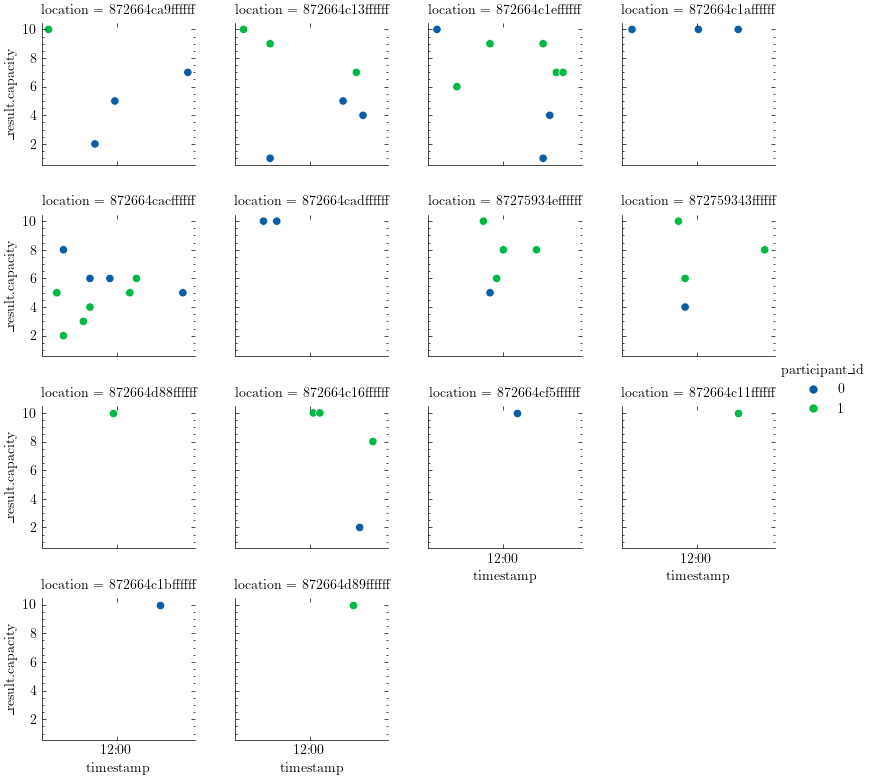

In [13]:
auction_tracking.sort_values(by=['time', 'location'], inplace=True)
g = sns.relplot(data=auction_tracking, x="timestamp", y="_result.capacity", hue="participant_id", col="location", col_wrap=4, kind="scatter", height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

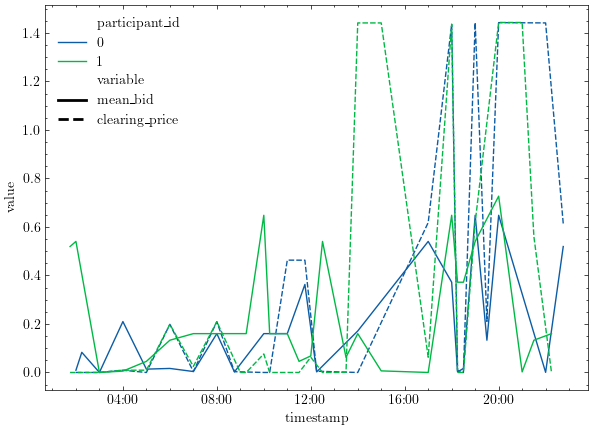

In [14]:
from matplotlib.lines import Line2D


fig, ax = plt.subplots(1,1, figsize=(7,5))

auction_tracking_long = auction_tracking.melt(id_vars=['timestamp', 'location', 'participant_id'], value_vars=['_result.clearing_price', '_bids.mean_bid'])
auction_tracking_long['variable'] = auction_tracking_long['variable'].astype('category')

sns.lineplot(data=auction_tracking_long, x="timestamp", y="value", hue="participant_id", style="variable", ax=ax)

handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='solid'))
handles.append(Line2D([0], [0], color='black', lw=2, linestyle='dashed'))
labels.extend(['mean_bid', 'clearing_price'])

ax.legend(handles=handles, labels=labels)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Vehicles

In [23]:
vehicle_tracking = pd.read_csv("data/output/tracking/vehicles.csv")

In [24]:
vehicle_tracking['_state'].apply(lambda x: set(eval(x))).value_counts()

_state
{1, 2, 3, 4, 1003}             1131
{1, 2, 3, 4, 1001, 1003}       1001
{1, 2, 3, 4, 5, 1003}           177
{1, 2, 3, 4, 5, 1001, 1003}     152
{1, 2, 1003}                     81
{1, 2, 3, 4}                     79
{1, 2}                           63
{1, 2, 3, 4, 1001}               60
{1, 2, 1001}                     50
{1, 2, 1003, 1001}               23
{1, 2, 3, 4, 5, 1001}            21
{1, 2, 3, 4, 5}                   9
{1, 2, 1003, 4}                   4
{1}                               4
{1, 2, 3}                         4
{1, 2, 4, 1001}                   3
{1, 2, 3, 1001, 1003}             3
{1, 2, 3, 1003}                   3
{1, 2, 3, 1001}                   3
{1, 1001}                         2
{1, 1003}                         2
{1, 2, 4}                         2
{1, 2, 4, 1001, 1003}             1
Name: count, dtype: int64

In [25]:
RECHARGE_THRESHOLD = 25 # ATTENTION: This is an approximation, we use dynamic ones per hour

vehicle_tracking['fleet_average_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.mean(eval(x)))
vehicle_tracking['fleet_number_low_SOC'] = vehicle_tracking['_current_state_of_charge'].apply(lambda x: np.count_nonzero(np.array(eval(x))< RECHARGE_THRESHOLD))

In [26]:
# rename time axis
vehicle_tracking['time'] = pd.to_datetime(vehicle_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

vehicle_tracking['timestamp'] = vehicle_tracking['time'].dt.strftime("%H:%M")

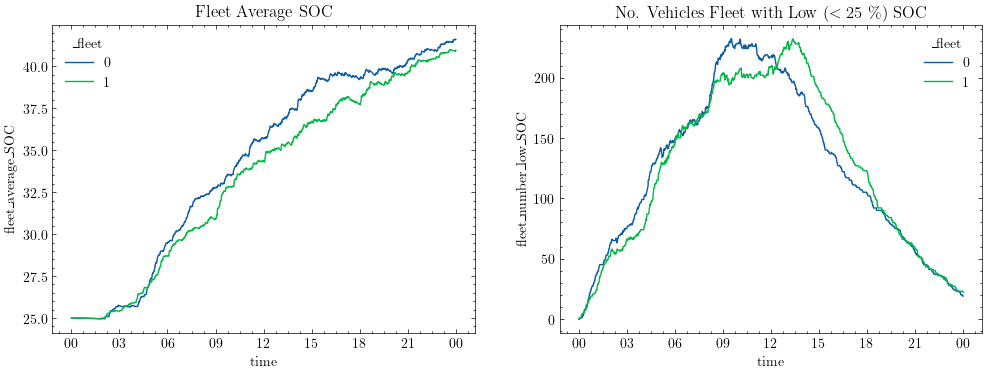

In [27]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12, 4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
sns.lineplot(data=vehicle_tracking, x='time', y='fleet_number_low_SOC', hue='_fleet', ax = ax[1])

ax[0].set_title('Fleet Average SOC')
ax[1].set_title(f'No. Vehicles Fleet with Low ($< {RECHARGE_THRESHOLD}$ \%) SOC')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [22]:
INITIALIZED = 0
PARKING = 1
DRIVING = 2
RELOCATING = 3
CHARGING = 4
PRE_SERVICE = 5
ONLINE = 6  # When the driver is online
OFFLINE = 7  # When the driver is offline
SOME_STATE = 1002
RESERVED = 1001
MOVING_TO_PICK_UP_POS = 1003

In [23]:
vehicle_tracking['_state_PARKING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PARKING))

vehicle_tracking['_state_CHARGING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == CHARGING))

vehicle_tracking['_state_DRIVING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == DRIVING))

vehicle_tracking['_state_RELOCATING'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RELOCATING))

vehicle_tracking['_state_PRE_SERVICE'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == PRE_SERVICE))

vehicle_tracking['_state_MOVING_TO_PICK_UP_POS'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == MOVING_TO_PICK_UP_POS))

vehicle_tracking['_state_RESERVED'] = vehicle_tracking['_state'].apply(lambda x: np.count_nonzero(np.array(eval(x)) == RESERVED))

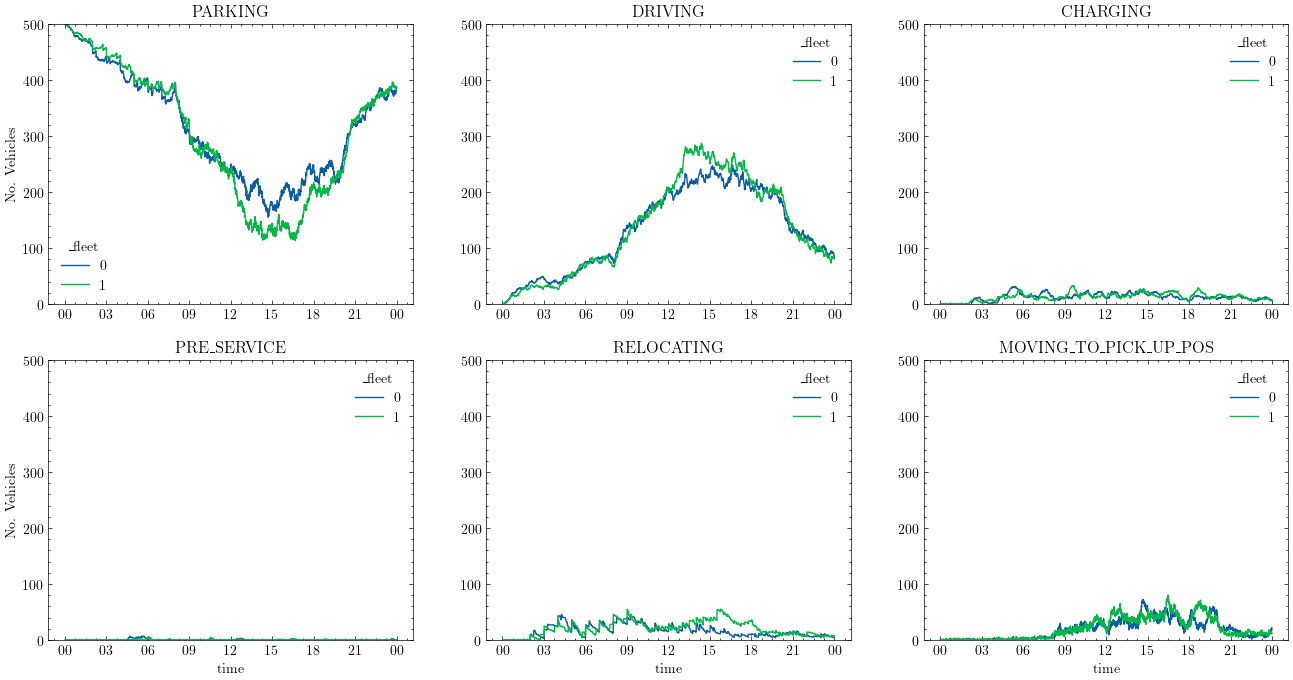

In [24]:
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(16, 8))
sns.lineplot(data=vehicle_tracking, x='time', y='_state_PARKING', hue='_fleet', ax=ax[0][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_DRIVING', hue='_fleet', ax=ax[0][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_CHARGING', hue='_fleet', ax=ax[0][2])

sns.lineplot(data=vehicle_tracking, x='time', y='_state_PRE_SERVICE', hue='_fleet', ax=ax[1][0])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_RELOCATING', hue='_fleet', ax=ax[1][1])
sns.lineplot(data=vehicle_tracking, x='time', y='_state_MOVING_TO_PICK_UP_POS', hue='_fleet', ax=ax[1][2])

ax[0][0].set_title('PARKING')
ax[0][1].set_title('DRIVING')
ax[0][2].set_title('CHARGING')

ax[1][0].set_title('PRE_SERVICE')
ax[1][1].set_title('RELOCATING')
ax[1][2].set_title('MOVING_TO_PICK_UP_POS')


for aa in ax:
    for i, a in enumerate(aa):
        a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
        a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))


        a.set_ylabel('No. Vehicles')
        a.set_ylim(0, parser.getint("EXPERIMENT_MANAGEMENT", "N_CARS"))
        a.yaxis.label.set_visible(False) if i > 0 else None

for a in ax[0]:
    a.xaxis.label.set_visible(False)

## Charging Stations

In [15]:
charging_station_tracking = pd.read_csv("data/output/tracking/charging_stations.csv")

In [16]:
CHARGING_STATION_CAPACITY = parser.getint("CHARGING_INFRASTRUCTURE", "CHARGING_STATION_CAPACITY")

In [17]:
charging_station_tracking['utilization'] = charging_station_tracking['_plugs.count'] / CHARGING_STATION_CAPACITY

charging_station_tracking['system_wide_utilization'] = charging_station_tracking.groupby('time')['utilization'].transform('mean')

In [18]:
# rename time axis
charging_station_tracking['time'] = pd.to_datetime(charging_station_tracking['time'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

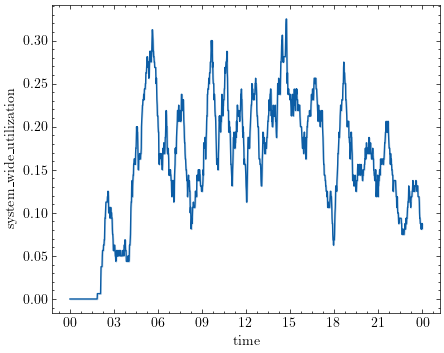

In [19]:
fig, ax = plt.subplots(1,1, figsize=(5,4))

sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

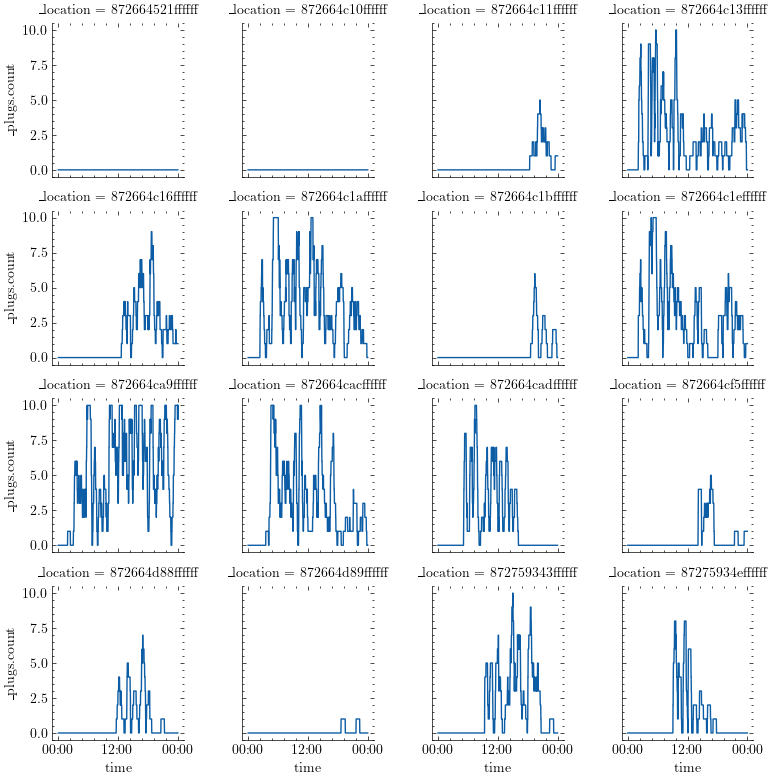

In [30]:
charging_station_tracking.sort_values(by=['time', '_location'], inplace=True)
g = sns.relplot(
    data=charging_station_tracking, x='time', y='_plugs.count', col='_location', kind='line', col_wrap=4, height=2)

axes = g.axes.flat

for a in axes:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=4))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Transactions

In [33]:
transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_transactions.csv")
transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_transactions.csv")

In [34]:
RESAMPLE_RATE = '1h'

In [35]:
transactions_fleet_0['timestamp'] = transactions_fleet_0['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_0['timestamp'] = pd.to_datetime(transactions_fleet_0['timestamp'], format="%H:%M:%S")
transactions_fleet_0_resampled = transactions_fleet_0.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

transactions_fleet_1['timestamp'] = transactions_fleet_1['time_end'].apply(SimulationTimeConverter.as_time)
transactions_fleet_1['timestamp'] = pd.to_datetime(transactions_fleet_1['timestamp'], format="%H:%M:%S")
transactions_fleet_1_resampled = transactions_fleet_1.resample(RESAMPLE_RATE, on = 'timestamp').agg({'state': 'value_counts'}).unstack()

In [36]:
# normalize
transactions_fleet_0_resampled = transactions_fleet_0_resampled.div(transactions_fleet_0_resampled.sum(axis=1), axis=0)

transactions_fleet_1_resampled = transactions_fleet_1_resampled.div(transactions_fleet_1_resampled.sum(axis=1), axis=0)

# rename time axis
transactions_fleet_0_resampled['timestamp'] = transactions_fleet_0_resampled.index.strftime("%H:%M")
transactions_fleet_0_resampled.set_index('timestamp', inplace=True)

transactions_fleet_1_resampled['timestamp'] = transactions_fleet_1_resampled.index.strftime("%H:%M")
transactions_fleet_1_resampled.set_index('timestamp', inplace=True)

In [37]:
transactions_fleet_0_resampled

state                    
state     Fulfilled    MISSED   REFUSED
timestamp                              
00:00      0.272727       NaN  0.727273
01:00      0.454545       NaN  0.545455
02:00      0.531915       NaN  0.468085
03:00      0.690909       NaN  0.309091
04:00      0.519481       NaN  0.480519
05:00      0.493333       NaN  0.506667
06:00      0.615385       NaN  0.384615
07:00      0.657407       NaN  0.342593
08:00      0.558442       NaN  0.441558
09:00      0.639498       NaN  0.360502
10:00      0.558480  0.020468  0.421053
11:00      0.638889  0.009259  0.351852
12:00      0.607235  0.002584  0.390181
13:00      0.631130       NaN  0.368870
14:00      0.619165  0.034398  0.346437
15:00      0.603814  0.076271  0.319915
16:00      0.631236  0.008677  0.360087
17:00      0.658301  0.081081  0.260618
18:00      0.629310  0.099138  0.271552
19:00      0.601202  0.090180  0.308617
20:00      0.639889  0.119114  0.240997
21:00      0.551471  0.183824  0.264706
22:00      0.592437  0.142857  0.264706
23:00      0.545455  0.241107  0.213439

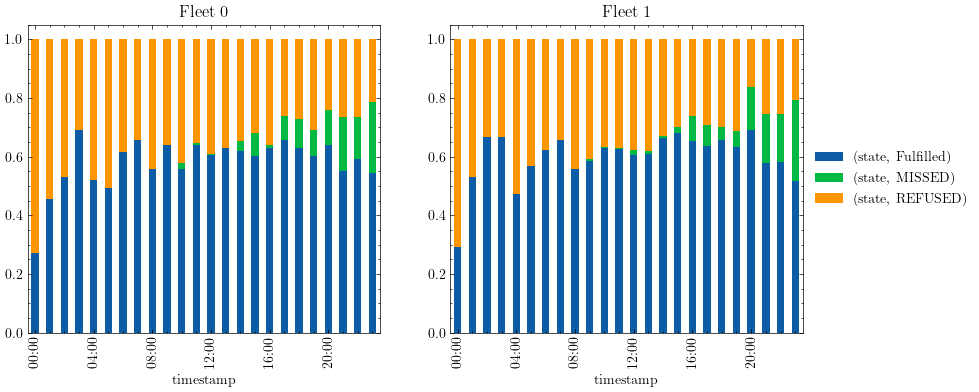

In [38]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

transactions_fleet_0_resampled.plot(kind = 'bar', stacked=True, ax=ax[0], legend=False)
transactions_fleet_1_resampled.plot(kind = 'bar', stacked=True, ax=ax[1], legend=True)

ax[1].legend(loc='center left', bbox_to_anchor=(1.0, 0.5))

ax[0].set_title('Fleet 0')
ax[1].set_title('Fleet 1')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    # a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

(0.0, 1.0)

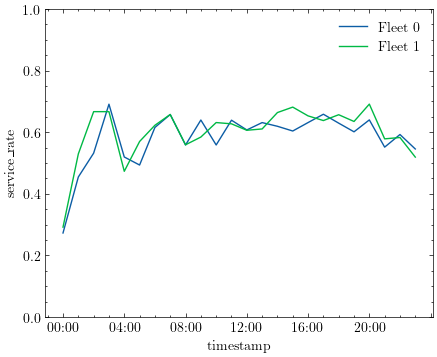

In [39]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

transactions_fleet_0_resampled['service_rate'] = transactions_fleet_0_resampled[('state', 'Fulfilled')]
transactions_fleet_1_resampled['service_rate'] = transactions_fleet_1_resampled[('state', 'Fulfilled')]

# service_rate_mean = transactions_fleet_0_resampled.reset_index()[['timestamp', 'service_rate']].join(transactions_fleet_1_resampled.reset_index()[['timestamp', 'service_rate']], on='timestamp')

sns.lineplot(data=transactions_fleet_0_resampled, x = transactions_fleet_0_resampled.index, y = 'service_rate', label='Fleet 0', ax=ax)
sns.lineplot(data=transactions_fleet_1_resampled, x = transactions_fleet_1_resampled.index, y = 'service_rate', label='Fleet 1', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
# ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

ax.set_ylim(0, 1.0)

### Vehilce Distance Travelled: Service vs. Operations

In [38]:
vehicle_tracking['fleet_vdt'] = vehicle_tracking['_vdt'].apply(lambda x: sum(eval(x)))

In [39]:
service_vdt_fleet_0 = transactions_fleet_0[transactions_fleet_0['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})
service_vdt_fleet_1 = transactions_fleet_1[transactions_fleet_1['state'] == 'Fulfilled'].resample(RESAMPLE_RATE, on = 'timestamp').agg({'distance': 'sum'})

In [40]:
service_vdt_fleet_0['cumsum'] = service_vdt_fleet_0.cumsum()
service_vdt_fleet_1['cumsum'] = service_vdt_fleet_1.cumsum()

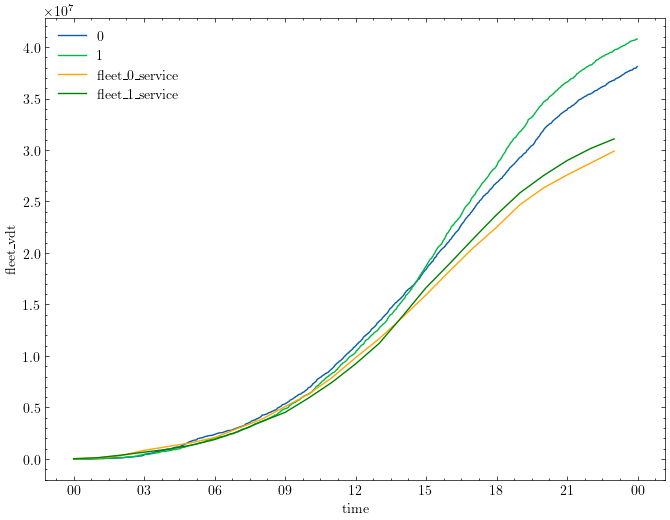

In [41]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_vdt', hue='_fleet', ax=ax)
sns.lineplot(data=service_vdt_fleet_0, x='timestamp', y='cumsum', color='orange', label='fleet_0_service', ax=ax)
sns.lineplot(data=service_vdt_fleet_1, x='timestamp', y='cumsum', color='green', label='fleet_1_service', ax=ax)

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [42]:
# share of operations VDT (excl customer serving)
hourly_vdt = vehicle_tracking.groupby('_fleet').resample(RESAMPLE_RATE, on = 'time').agg({'fleet_vdt': 'max'}).unstack(level=0).rename(columns={0: 'fleet_0_vdt_cumsum', 1: 'fleet_1_vdt_cumsum'}).droplevel(0, axis=1)

In [43]:
hourly_vdt = hourly_vdt.join(service_vdt_fleet_0)

hourly_vdt = hourly_vdt.join(service_vdt_fleet_1, rsuffix='_service_fleet_1')

hourly_vdt.rename(columns={'distance': 'distance_service_fleet_0', 'cumsum': 'cumsum_service_fleet_0'}, inplace=True)

hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_0']) / hourly_vdt['fleet_0_vdt_cumsum']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt_cumsum'] - hourly_vdt['cumsum_service_fleet_1']) / hourly_vdt['fleet_1_vdt_cumsum']

In [44]:
hourly_vdt['fleet_0_vdt'] = hourly_vdt['fleet_0_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_0_vdt_cumsum'].iloc[0])

hourly_vdt['fleet_1_vdt'] = hourly_vdt['fleet_1_vdt_cumsum'].diff().fillna(hourly_vdt['fleet_1_vdt_cumsum'].iloc[0])


In [45]:
hourly_vdt['fleet_0_ratio_of_empty_vdt'] = (hourly_vdt['fleet_0_vdt'] - hourly_vdt['distance_service_fleet_0']) / hourly_vdt['fleet_0_vdt']

hourly_vdt['fleet_1_ratio_of_empty_vdt'] = (hourly_vdt['fleet_1_vdt'] - hourly_vdt['distance_service_fleet_1']) / hourly_vdt['fleet_1_vdt']

In [46]:
hourly_vdt.head()

,fleet_0_vdt_cumsum,fleet_1_vdt_cumsum,distance_service_fleet_0,cumsum_service_fleet_0,distance_service_fleet_1,cumsum_service_fleet_1,fleet_0_ratio_of_empty_vdt,fleet_1_ratio_of_empty_vdt,fleet_0_vdt,fleet_1_vdt
time,,,,,,,,,,
1900-01-01 00:00:00,2.905420e+04,3.188370e+04,21931.388886,2.193139e+04,25789.824833,25789.824833,0.245156,0.191128,29054.203513,31883.700776
1900-01-01 01:00:00,9.723660e+04,1.403100e+05,61950.379712,8.388177e+04,94962.266623,120752.091456,0.091402,0.124177,68182.396990,108426.331124
1900-01-01 02:00:00,3.653297e+05,4.277232e+05,228282.503854,3.121643e+05,249505.880711,370257.972167,0.148495,0.131891,268093.067176,287413.211665
1900-01-01 03:00:00,9.521546e+05,7.962688e+05,525341.769215,8.375060e+05,288539.007945,658796.980112,0.104773,0.217087,586824.925955,368545.593958
1900-01-01 04:00:00,1.701580e+06,1.334336e+06,364673.302795,1.202179e+06,283961.831954,942758.812065,0.513396,0.472256,749425.808051,538067.284045


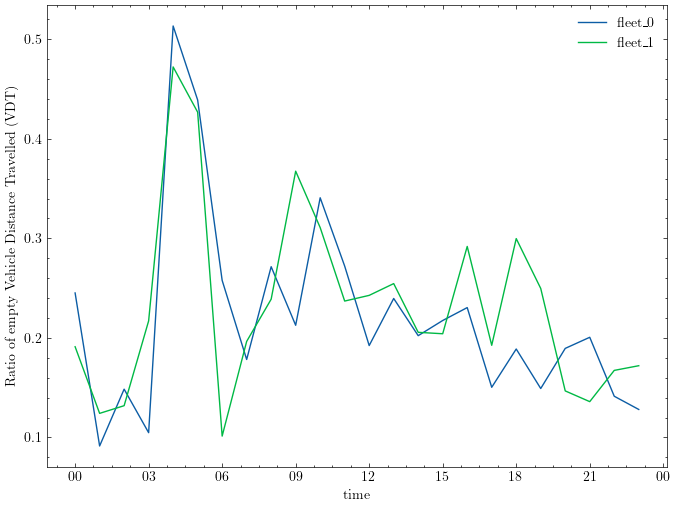

In [47]:
fig, ax = plt.subplots(1,1, figsize=(8, 6))

sns.lineplot(data=hourly_vdt, x='time', y='fleet_0_ratio_of_empty_vdt', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_vdt, x='time', y='fleet_1_ratio_of_empty_vdt', label='fleet_1', ax=ax)

ax.set_ylabel('Ratio of empty Vehicle Distance Travelled (VDT)')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

## Service Tasks

In [40]:
task_transactions_fleet_0 = pd.read_csv("data/output/transactions/fleet_0_task_transactions.csv")

task_transactions_fleet_1 = pd.read_csv("data/output/transactions/fleet_1_task_transactions.csv")

In [41]:
task_transactions_fleet_0['timestamp'] = task_transactions_fleet_0['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_0['timestamp'] = pd.to_datetime(task_transactions_fleet_0['timestamp'], format="%H:%M:%S")

task_transactions_fleet_1['timestamp'] = task_transactions_fleet_1['start_time'].apply(SimulationTimeConverter.as_time)
task_transactions_fleet_1['timestamp'] = pd.to_datetime(task_transactions_fleet_1['timestamp'], format="%H:%M:%S")

task_transactions_fleet_0['duration'] = task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['start_time']

task_transactions_fleet_1['duration'] = task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['start_time']

!! probably we should sanity-check why duration < waiting_time + charging_duration

In [42]:
task_transactions_fleet_0

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration
0,121,156.992171,80,TaskState.FINISHED,0,872664c1effffff,8.810103,30.802273,25.668561,1900-01-01 02:01:00,35.992171
1,121,158.237675,72,TaskState.FINISHED,0,872664c1effffff,7.611359,30.849034,25.707528,1900-01-01 02:01:00,37.237675
2,121,158.758222,51,TaskState.FINISHED,0,872664c1effffff,8.124482,31.882704,26.568920,1900-01-01 02:01:00,37.758222
3,121,171.570348,149,TaskState.FINISHED,0,872664c1effffff,9.160737,30.731084,25.609237,1900-01-01 02:01:00,50.570348
4,136,173.106181,182,TaskState.FINISHED,0,872664c1affffff,7.457062,30.563243,25.469369,1900-01-01 02:16:00,37.106181
...,...,...,...,...,...,...,...,...,...,...,...
479,1381,1440.000000,324,TaskState.EXECUTING_CHARGING,0,872664ca9ffffff,-56.830067,3.169933,2.641611,1900-01-01 23:01:00,59.000000
480,1396,1440.000000,415,TaskState.EXECUTING_RELOCATION,0,872664ca9ffffff,NaN,NaN,NaN,1900-01-01 23:16:00,44.000000
481,1396,1440.000000,433,TaskState.EXECUTING_RELOCATION,0,872664ca9ffffff,NaN,NaN,NaN,1900-01-01 23:16:00,44.000000
482,1396,1440.000000,444,TaskState.EXECUTING_RELOCATION,0,872664ca9ffffff,NaN,NaN,NaN,1900-01-01 23:16:00,44.000000


In [43]:
display(task_transactions_fleet_0.value_counts(subset=['state']))
display(task_transactions_fleet_1.value_counts(subset=['state']))

state                         
TaskState.FINISHED                473
TaskState.EXECUTING_CHARGING        7
TaskState.EXECUTING_RELOCATION      4
Name: count, dtype: int64

state                         
TaskState.FINISHED                473
TaskState.EXECUTING_CHARGING        7
TaskState.EXECUTING_RELOCATION      7
Name: count, dtype: int64

<Axes: xlabel='charging_duration', ylabel='kWh_charged'>

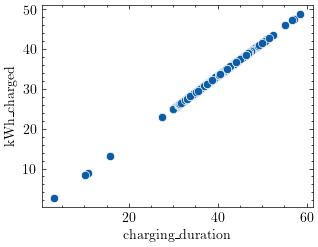

In [44]:
# check linearity
sns.scatterplot(data=task_transactions_fleet_0, x='charging_duration', y='kWh_charged')

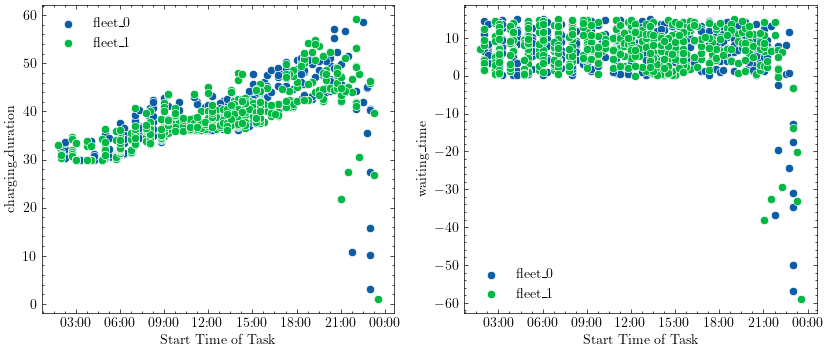

In [45]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='charging_duration', label='fleet_0', ax=ax[0])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='charging_duration', label='fleet_1', ax=ax[0])

sns.scatterplot(data=task_transactions_fleet_0, x='timestamp', y='waiting_time', label='fleet_0', ax=ax[1])
sns.scatterplot(data=task_transactions_fleet_1, x='timestamp', y='waiting_time', label='fleet_1', ax=ax[1])

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [46]:
hourly_tasks = pd.merge(
    task_transactions_fleet_0.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_0', 'waiting_time': 'avg_waiting_time_fleet_0', 'charging_duration': 'avg_charging_duration_fleet_0'}),
    task_transactions_fleet_1.resample('h', on='timestamp').agg({'fleet': 'count', 'waiting_time': 'mean', 'charging_duration': 'mean'}).rename(columns={'fleet': 'tasks_finished_fleet_1', 'waiting_time': 'avg_waiting_time_fleet_1', 'charging_duration': 'avg_charging_duration_fleet_1'}),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

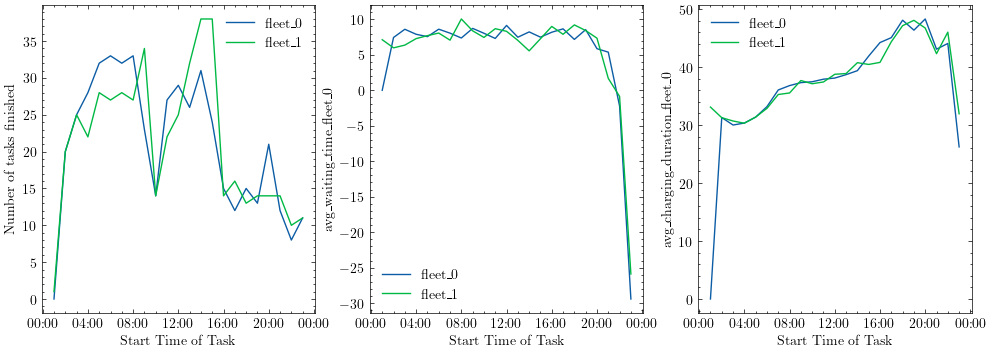

In [48]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='tasks_finished_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[1])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[1])

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_0', label='fleet_0', ax=ax[2])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_charging_duration_fleet_1', label='fleet_1', ax=ax[2])

ax[0].set_ylabel("Number of tasks finished")

for a in ax:
    a.set_xlabel('Start Time of Task')
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

In [56]:
date_range = range(0,1440,15)

hourly_events_fleet_0 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_0': [((task_transactions_fleet_0['start_time'] <= i) & (task_transactions_fleet_0['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_0.set_index('time', inplace=True)

hourly_events_fleet_1 = pd.DataFrame({'time': date_range, 'events_ongoing_fleet_1': [((task_transactions_fleet_1['start_time'] <= i) & (task_transactions_fleet_1['end_time'] > i)).sum() for i in date_range]})
hourly_events_fleet_1.set_index('time', inplace=True)

hourly_events_ongoing = pd.merge(
    hourly_events_fleet_0,
    hourly_events_fleet_1,
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)

hourly_events_ongoing.reset_index(inplace=True)

In [57]:
hourly_events_ongoing['timestamp'] = hourly_events_ongoing['time'].apply(SimulationTimeConverter.as_time)
hourly_events_ongoing['timestamp'] = pd.to_datetime(hourly_events_ongoing['timestamp'], format="%H:%M:%S")

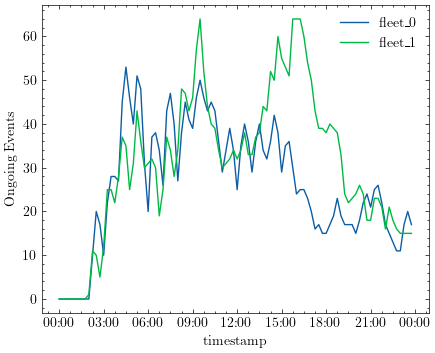

In [58]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5, 4))

sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_0', label='fleet_0', ax=ax)
sns.lineplot(data=hourly_events_ongoing, x='timestamp', y='events_ongoing_fleet_1', label='fleet_1', ax=ax)

ax.set_ylabel('Ongoing Events')

ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))


In [59]:
task_transactions_fleet_0['timeslot'] = (task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) - ((task_transactions_fleet_0['end_time'] - task_transactions_fleet_0['charging_duration']) % 15)

task_transactions_fleet_1['timeslot'] = (task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) - ((task_transactions_fleet_1['end_time'] - task_transactions_fleet_1['charging_duration']) % 15)

In [60]:
tasks_incl_price = pd.concat(
    [task_transactions_fleet_0,task_transactions_fleet_1]
    ).merge(
        auction_tracking[['time', '_result.clearing_price']], 
        how='left', 
        left_on = 'timeslot', 
        right_on = "time"
        )

In [61]:
kWh_price = parser.getfloat("AUTONOMOUS_CAR", "CHARGING_COST_PER_KWH")

tasks_incl_price['charging_cost'] = tasks_incl_price['kWh_charged'] * kWh_price

In [62]:
tasks_incl_price.head()

,start_time,end_time,vehicle,state,fleet,charging_station,waiting_time,charging_duration,kWh_charged,timestamp,duration,timeslot,time,_result.clearing_price,charging_cost
0,121,156.992171,80,TaskState.FINISHED,0,872664c1effffff,8.810103,30.802273,25.668561,1900-01-01 02:01:00,35.992171,120.0,120.0,0.0,11.037481
1,121,156.992171,80,TaskState.FINISHED,0,872664c1effffff,8.810103,30.802273,25.668561,1900-01-01 02:01:00,35.992171,120.0,120.0,0.0,11.037481
2,121,158.237675,72,TaskState.FINISHED,0,872664c1effffff,7.611359,30.849034,25.707528,1900-01-01 02:01:00,37.237675,120.0,120.0,0.0,11.054237
3,121,158.237675,72,TaskState.FINISHED,0,872664c1effffff,7.611359,30.849034,25.707528,1900-01-01 02:01:00,37.237675,120.0,120.0,0.0,11.054237
4,121,158.758222,51,TaskState.FINISHED,0,872664c1effffff,8.124482,31.882704,26.568920,1900-01-01 02:01:00,37.758222,120.0,120.0,0.0,11.424635


In [63]:
hourly_costs = tasks_incl_price.groupby('fleet').resample('1h', on='timestamp').agg({'charging_cost': 'sum', '_result.clearing_price': 'sum'}).reset_index()
hourly_costs.rename(columns={'_result.clearing_price': 'reservation_cost'}, inplace=True)

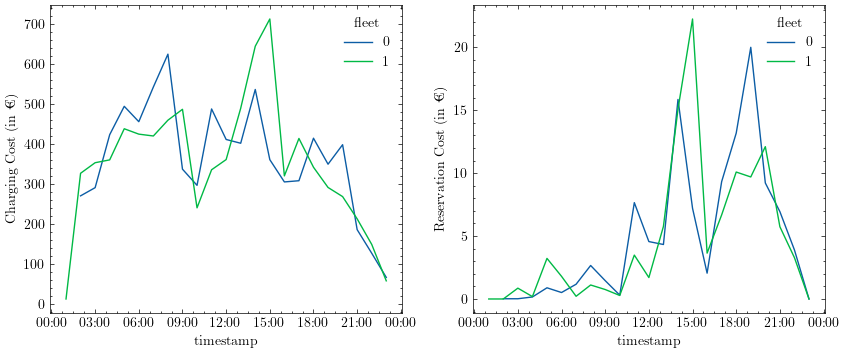

In [64]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

sns.lineplot(hourly_costs, x='timestamp', y='charging_cost', hue='fleet', ax=ax[0])
sns.lineplot(hourly_costs, x='timestamp', y='reservation_cost', hue='fleet', ax=ax[1])

ax[0].set_ylabel('Charging Cost (in €)')
ax[1].set_ylabel('Reservation Cost (in €)')

for a in ax:
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))

## Benchmark: Single Infrastructure, No Coordination

In [8]:
benchmark_no_coordination = pd.read_csv("data/output/benchmarks/time_related_kpi_500.csv")

In [11]:
benchmark_no_coordination

,timestamp,all_vehicles_avg_SOC,all_vehicles_waiting_times,all_stations_utilization_rate
0,5,24.999690,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
1,10,24.999282,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
2,15,24.998242,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
3,20,24.996023,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
4,25,24.993021,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]"
...,...,...,...,...
282,1415,31.071695,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
283,1420,31.038341,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
284,1425,31.016514,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."
285,1430,31.009206,"[[0.0], [0.0], [0.0], [0.0], [0.0], [], [0.0],...","[0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.1..."


<Axes: xlabel='timestamp'>

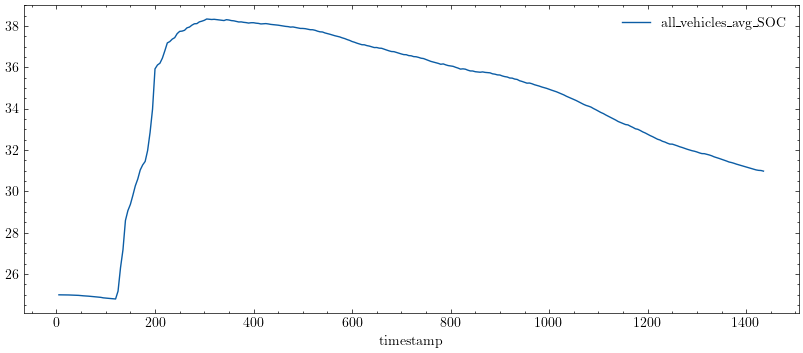

In [10]:
benchmark_no_coordination.plot(x='timestamp', y='all_vehicles_avg_SOC', figsize=(10, 4))

In [12]:
benchmark_no_coordination['charging_utilization'] = benchmark_no_coordination['all_stations_utilization_rate'].apply(lambda x: np.mean(eval(x)))

<Axes: xlabel='timestamp'>

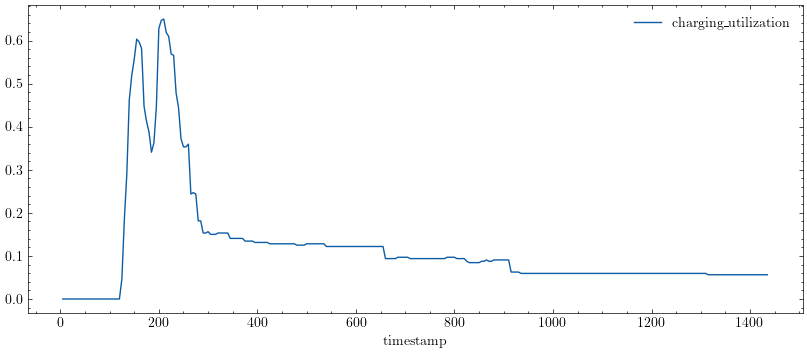

In [13]:
benchmark_no_coordination.plot(x='timestamp', y='charging_utilization', figsize=(10, 4))

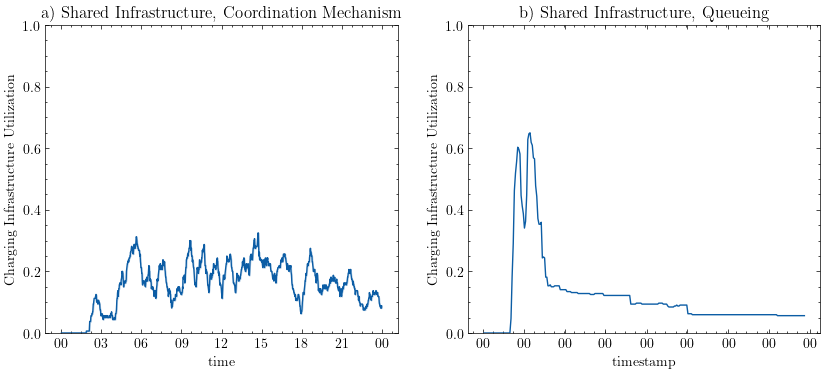

In [22]:
# compare to our scenario
benchmark_no_coordination['time'] = pd.to_datetime(benchmark_no_coordination['timestamp'].apply(SimulationTimeConverter.as_time), format="%H:%M:%S")

fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=charging_station_tracking, x='time', y='system_wide_utilization', ax=ax[0])
ax[0].set_ylabel('Charging Infrastructure Utilization')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='charging_utilization', ax=ax[1])
ax[1].set_ylabel('Charging Infrastructure Utilization')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 1.0)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

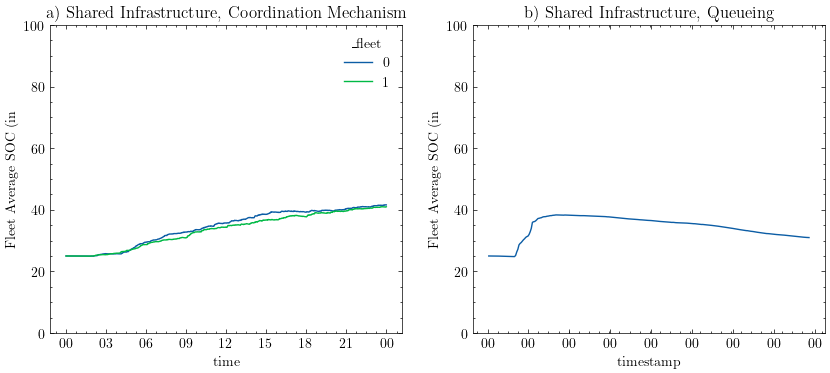

In [29]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=vehicle_tracking, x='time', y='fleet_average_SOC', hue='_fleet', ax = ax[0])
ax[0].set_ylabel('Fleet Average SOC (in %)')
ax[0].set_title('a) Shared Infrastructure, Coordination Mechanism')

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='all_vehicles_avg_SOC', ax=ax[1])
ax[1].set_ylabel('Fleet Average SOC (in %)')
ax[1].set_title('b) Shared Infrastructure, Queueing')

for a in ax:
    a.set_ylim(0, 100)
    a.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=12))
    a.xaxis.set_major_formatter(mdates.DateFormatter('%H'))

In [58]:
benchmark_no_coordination['vehicles_avg_waiting_times'] = benchmark_no_coordination['all_vehicles_waiting_times'].apply(lambda x: np.mean([y[0] for y in eval(x) if len(y) > 0]))

<Axes: xlabel='timestamp', ylabel='vehicles_avg_waiting_times'>

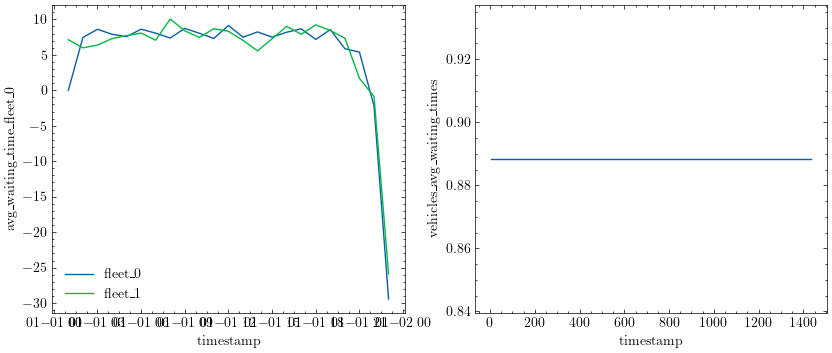

In [59]:
# compare to our scenario
fig, ax = plt.subplots(1,2, figsize=(10,4))

sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_0', label='fleet_0', ax=ax[0])
sns.lineplot(data=hourly_tasks, x='timestamp', y='avg_waiting_time_fleet_1', label='fleet_1', ax=ax[0])

sns.lineplot(data=benchmark_no_coordination, x='timestamp', y='vehicles_avg_waiting_times', ax=ax[1])


In [31]:
metrics_no_coordination = pd.read_csv("data/output/benchmarks/end_of_sim_kpi_500.csv")

In [32]:
metrics_no_coordination

,fleet_0_total_fulfilled_trips_ride_hailing,fleet_0_total_missed_trips_ride_hailing,fleet_1_total_fulfilled_trips_ride_hailing,fleet_1_total_missed_trips_ride_hailing,fleet_0_mean_distance_to_charging_station,fleet_1_mean_distance_to_charging_station
0,5291,2425,5225,2340,1672.85863,1732.391686


In [63]:
display(transactions_fleet_0.value_counts('state'))
display(transactions_fleet_1.value_counts('state'))

state
Fulfilled    3974
REFUSED      2176
MISSED        386
Name: count, dtype: int64

state
Fulfilled    4053
REFUSED      2088
MISSED        357
Name: count, dtype: int64

In [66]:
pd.DataFrame([
    {
        'fleet': 0,
        'service_rate_coordination': sum(transactions_fleet_0['state'] == 'Fulfilled') / transactions_fleet_0.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_0_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_0_total_missed_trips_ride_hailing'])
    },
    {
        'fleet': 1,
        'service_rate_coordination': sum(transactions_fleet_1['state'] == 'Fulfilled') / transactions_fleet_1.shape[0],
        'service_rate_queuing': metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] / (metrics_no_coordination.at[0, 'fleet_1_total_fulfilled_trips_ride_hailing'] + metrics_no_coordination.at[0, 'fleet_1_total_missed_trips_ride_hailing'])
    }    
])

,fleet,service_rate_coordination,service_rate_queuing
0,0,0.608017,0.685718
1,1,0.623730,0.690681


### other stuff

<Axes: xlabel='waiting_time', ylabel='pick_up_time'>

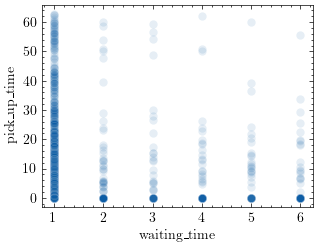

In [68]:
sns.scatterplot(transactions_fleet_0, x='waiting_time', y='pick_up_time', alpha=.1)

In [69]:
transactions_fleet_0['pick_up_time'].describe()

count    6551.000000
mean        4.126147
std         8.132946
min         0.000000
25%         0.000000
50%         1.278793
75%         4.707706
max        62.776211
Name: pick_up_time, dtype: float64